### Concatenating and Merging Data

In [1]:
import numpy as np
import pandas as pd

In [2]:
# we will load up two deparate sources of data then merge together
aapl = pd.read_csv('../data/A.csv')
sp500 = pd.read_csv('../data/S.csv')
aapl['Ticker'] = 'AAPL' # add a brand new column to the data
aapl

,Date,Open,High,Low,Close,Adj Close,Volume,Ticker
0,1980-12-12,0.513393,0.515625,0.513393,0.513393,0.410525,117258400.0,AAPL
1,1980-12-15,0.488839,0.488839,0.486607,0.486607,0.389106,43971200.0,AAPL
2,1980-12-16,0.453125,0.453125,0.450893,0.450893,0.360548,26432000.0,AAPL
3,1980-12-17,0.462054,0.464286,0.462054,0.462054,0.369472,21610400.0,AAPL
4,1980-12-18,0.475446,0.477679,0.475446,0.475446,0.380182,18362400.0,AAPL
...,...,...,...,...,...,...,...,...
9739,2019-07-30,208.759995,210.160004,207.309998,208.779999,208.779999,33935700.0,AAPL
9740,2019-07-31,216.419998,221.369995,211.300003,213.039993,213.039993,69281400.0,AAPL
9741,2019-08-01,213.899994,218.029999,206.740005,208.429993,208.429993,54017900.0,AAPL
9742,2019-08-02,205.529999,206.429993,201.630005,204.020004,204.020004,40862100.0,AAPL


In [3]:
a = 1
b = 2
a
b

2

In [4]:
sp500['Ticker'] = 'SP500'
# replace date strings with actual date values
sp500['Date'] = pd.to_datetime( sp500['Date'], format='%m/%d/%y' )
aapl['Date'] = pd.to_datetime( aapl['Date'], format='%Y-%m-%d' )
aapl.info() # careful - an info line will ALWAYS render output
sp500

<class 'pandas.DataFrame'>
RangeIndex: 9744 entries, 0 to 9743
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   Date       9744 non-null   datetime64[us]
 1   Open       9743 non-null   float64       
 2   High       9743 non-null   float64       
 3   Low        9743 non-null   float64       
 4   Close      9743 non-null   float64       
 5   Adj Close  9743 non-null   float64       
 6   Volume     9743 non-null   float64       
 7   Ticker     9744 non-null   str           
dtypes: datetime64[us](1), float64(6), str(1)
memory usage: 648.4 KB


,Date,Open,High,Low,Close,Adj Close,Volume,Ticker
0,2013-09-30,1687.260010,1687.260010,1674.989990,1681.550049,1681.550049,3308630000,SP500
1,2013-10-01,1682.410034,1696.550049,1682.069946,1695.000000,1695.000000,3238690000,SP500
2,2013-10-02,1691.900024,1693.869995,1680.339966,1693.869995,1693.869995,3148600000,SP500
3,2013-10-03,1692.349976,1692.349976,1670.359985,1678.660034,1678.660034,3279650000,SP500
4,2013-10-04,1678.790039,1691.939941,1677.329956,1690.500000,1690.500000,2880270000,SP500
...,...,...,...,...,...,...,...,...
1255,2018-09-24,2921.830078,2923.790039,2912.629883,2919.370117,2919.370117,3372210000,SP500
1256,2018-09-25,2921.750000,2923.949951,2913.699951,2915.560059,2915.560059,3285480000,SP500
1257,2018-09-26,2916.979980,2931.149902,2903.280029,2905.969971,2905.969971,3388620000,SP500
1258,2018-09-27,2911.649902,2927.219971,2909.270020,2914.000000,2914.000000,3060850000,SP500


In [5]:
# we may concaternate these dataFrames
combined = pd.concat([aapl, sp500])
combined # this gives us a lot of concat data

,Date,Open,High,Low,Close,Adj Close,Volume,Ticker
0,1980-12-12,0.513393,0.515625,0.513393,0.513393,0.410525,1.172584e+08,AAPL
1,1980-12-15,0.488839,0.488839,0.486607,0.486607,0.389106,4.397120e+07,AAPL
2,1980-12-16,0.453125,0.453125,0.450893,0.450893,0.360548,2.643200e+07,AAPL
3,1980-12-17,0.462054,0.464286,0.462054,0.462054,0.369472,2.161040e+07,AAPL
4,1980-12-18,0.475446,0.477679,0.475446,0.475446,0.380182,1.836240e+07,AAPL
...,...,...,...,...,...,...,...,...
1255,2018-09-24,2921.830078,2923.790039,2912.629883,2919.370117,2919.370117,3.372210e+09,SP500
1256,2018-09-25,2921.750000,2923.949951,2913.699951,2915.560059,2915.560059,3.285480e+09,SP500
1257,2018-09-26,2916.979980,2931.149902,2903.280029,2905.969971,2905.969971,3.388620e+09,SP500
1258,2018-09-27,2911.649902,2927.219971,2909.270020,2914.000000,2914.000000,3.060850e+09,SP500


In [6]:
merged = sp500.merge(aapl, left_on=['Date'], right_on=['Date'], suffixes=('_sp500', '_aapl'))

In [7]:
merged

,Date,Open_sp500,High_sp500,Low_sp500,Close_sp500,Adj Close_sp500,Volume_sp500,Ticker_sp500,Open_aapl,High_aapl,Low_aapl,Close_aapl,Adj Close_aapl,Volume_aapl,Ticker_aapl
0,2013-09-30,1687.260010,1687.260010,1674.989990,1681.550049,1681.550049,3308630000,SP500,68.178574,68.808571,67.772858,68.107140,61.347630,65039100.0,AAPL
1,2013-10-01,1682.410034,1696.550049,1682.069946,1695.000000,1695.000000,3238690000,SP500,68.349998,69.877144,68.339996,69.708572,62.790127,88470900.0,AAPL
2,2013-10-02,1691.900024,1693.869995,1680.339966,1693.869995,1693.869995,3148600000,SP500,69.375717,70.257141,69.107140,69.937141,62.996002,72296000.0,AAPL
3,2013-10-03,1692.349976,1692.349976,1670.359985,1678.660034,1678.660034,3279650000,SP500,70.072861,70.335716,68.677139,69.058571,62.204636,80688300.0,AAPL
4,2013-10-04,1678.790039,1691.939941,1677.329956,1690.500000,1690.500000,2880270000,SP500,69.122856,69.228569,68.371429,69.004288,62.155735,64717100.0,AAPL
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1255,2018-09-24,2921.830078,2923.790039,2912.629883,2919.370117,2919.370117,3372210000,SP500,216.820007,221.259995,216.630005,220.789993,218.242233,27693400.0,AAPL
1256,2018-09-25,2921.750000,2923.949951,2913.699951,2915.560059,2915.560059,3285480000,SP500,219.750000,222.820007,219.699997,222.190002,219.626099,24554400.0,AAPL
1257,2018-09-26,2916.979980,2931.149902,2903.280029,2905.969971,2905.969971,3388620000,SP500,221.000000,223.750000,219.759995,220.419998,217.876511,23984700.0,AAPL
1258,2018-09-27,2911.649902,2927.219971,2909.270020,2914.000000,2914.000000,3060850000,SP500,223.820007,226.440002,223.539993,224.949997,222.354248,30181200.0,AAPL


### Plotting charts

In [8]:
import matplotlib.pyplot as plt
%matplotlib # the leading % sign is an 'automagical' call
# in previous Jupyter this allowd code to run without calls
# is was used for file open/read/write, for plotting, for random number generators
# for calling O/S tools

<Axes: xlabel='Date', ylabel='Close'>

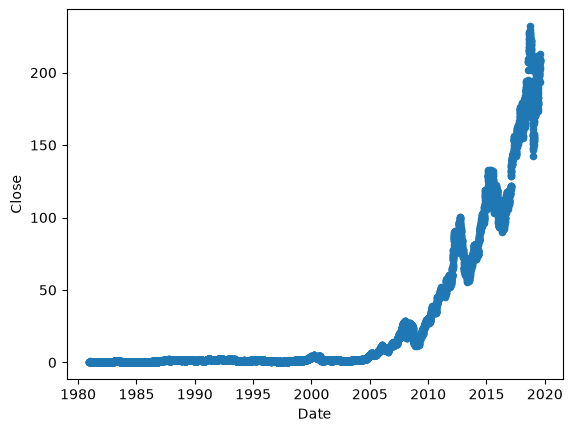

In [9]:
# here we use Pandas plotting capabilities
aapl.plot(kind='scatter', x='Date', y='Close')